# 04R — Regressão com 14 features e validação temporal

Este notebook é uma versão focada **somente no problema de regressão**:

> prever `target_dias_atraso`.

Ele mantém a lógica temporal do notebook 04/04B, mas usa apenas **14 variáveis** e remove toda a parte de classificação.

Modelos comparados:
- Random Forest Regressor
- Extra Trees Regressor
- HistGradientBoosting Regressor

A seleção do melhor modelo é feita pelo **MAE ponderado médio nos folds temporais**.
O teste final permanece reservado para avaliação final.

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)

RANDOM_STATE = 42

## 1. Carregar o dataset

In [6]:
CANDIDATE_PATHS = [
    Path("C:\\Users\\Gabriel\\OneDrive\\Documentos\\projeto_previsao_termino_obras\\data\\processed\\dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("/mnt/data/modelagem_outputs/processed/dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("/mnt/data/dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("modelagem_outputs/processed/dataset_modelagem_obras_snapshots_enriquecido.csv"),
    Path("dataset_modelagem_obras_snapshots_enriquecido.csv"),
]

DATASET_PATH = next(
    (p for p in CANDIDATE_PATHS if p.exists()),
    None,
)

if DATASET_PATH is None:
    raise FileNotFoundError(
        "Dataset enriquecido não encontrado. Ajuste DATASET_PATH."
    )

df = pd.read_csv(
    DATASET_PATH,
    low_memory=False,
    encoding="utf-8-sig",
)

for col in ["data_corte", "data_conclusao_definitiva"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

print("Dataset:", DATASET_PATH)
print("Shape:", df.shape)
print("Contratos:", df["id_contrato"].nunique())

Dataset: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\processed\dataset_modelagem_obras_snapshots_enriquecido.csv
Shape: (633, 109)
Contratos: 48


## 2. Definição das 14 features

As 14 variáveis são as mesmas selecionadas na versão reduzida do notebook 04B.

In [7]:
NUMERIC_FEATURES = ['prazo_original_dias', 'perc_desconto_modelo', 'pct_prazo_consumido', 'dias_restantes_prazo_vigente', 'pct_dias_aditados_sobre_prazo_original', 'qtd_aditivos_valor', 'pct_parcelas_atrasadas', 'dias_desde_ultima_parcela_concluida', 'pct_financeiro_liberado', 'atraso_medio_liberacao_dias', 'gap_prazo_execucao', 'gap_prazo_financeiro']

CATEGORICAL_FEATURES = ['classificacao_contrato', 'id_setor_divisao']

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

assert len(FEATURES) == 14
assert len(FEATURES) == len(set(FEATURES))

required = [
    "id_contrato",
    "data_corte",
    "data_conclusao_definitiva",
    "target_dias_atraso",
    "flag_apto_treino",
    "sample_weight_contrato",
    "split_contrato_temporal",
] + FEATURES

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        f"Colunas ausentes no dataset: {missing}"
    )

print("Features numéricas:", len(NUMERIC_FEATURES))
print("Features categóricas:", len(CATEGORICAL_FEATURES))
print("Total:", len(FEATURES))
display(pd.DataFrame({"feature": FEATURES}))

Features numéricas: 12
Features categóricas: 2
Total: 14


,feature
0,prazo_original_dias
1,perc_desconto_modelo
2,pct_prazo_consumido
3,dias_restantes_prazo_vigente
4,pct_dias_aditados_sobre_prazo_original
5,qtd_aditivos_valor
6,pct_parcelas_atrasadas
7,dias_desde_ultima_parcela_concluida
8,pct_financeiro_liberado
9,atraso_medio_liberacao_dias


## 3. Base de regressão

Usamos apenas snapshots marcados como aptos para treinamento.

In [8]:
reg_all = df[
    df["flag_apto_treino"].eq(1)
].copy()

reg_all = reg_all[
    reg_all["target_dias_atraso"].notna()
].copy()

print("Snapshots de regressão:", len(reg_all))
print("Contratos:", reg_all["id_contrato"].nunique())
print()
display(reg_all["target_dias_atraso"].describe())

Snapshots de regressão: 585
Contratos: 48



count    585.000000
mean      46.309402
std       89.379894
min        0.000000
25%        0.000000
50%        0.000000
75%       38.000000
max      380.000000
Name: target_dias_atraso, dtype: float64

## 4. Separação temporal: desenvolvimento e teste final

O conjunto `test` definido no dataset continua sendo o teste final.
Os demais contratos formam o conjunto de desenvolvimento.

In [9]:
test_contracts = (
    reg_all.loc[
        reg_all["split_contrato_temporal"].astype(str).str.lower().eq("test"),
        "id_contrato",
    ]
    .drop_duplicates()
    .tolist()
)

development_contracts = (
    reg_all.loc[
        ~reg_all["id_contrato"].isin(test_contracts),
        ["id_contrato", "data_conclusao_definitiva"],
    ]
    .drop_duplicates("id_contrato")
    .sort_values("data_conclusao_definitiva")
    ["id_contrato"]
    .tolist()
)

print("Contratos desenvolvimento:", len(development_contracts))
print("Contratos teste final:", len(test_contracts))
print("Teste final:", test_contracts)

Contratos desenvolvimento: 40
Contratos teste final: 8
Teste final: [173, 201, 254, 283, 287, 317, 342, 377]


## 5. Folds temporais expansivos

Mantemos quatro janelas de validação temporal:
- fold 1: primeiros 20 contratos para treino, próximos 5 para validação;
- fold 2: primeiros 25 para treino, próximos 5;
- fold 3: primeiros 30 para treino, próximos 5;
- fold 4: primeiros 35 para treino, próximos 5.

In [10]:
folds = []

for fold_number, train_end in enumerate([20, 25, 30, 35], start=1):
    validation_end = train_end + 5

    train_ids = development_contracts[:train_end]
    validation_ids = development_contracts[train_end:validation_end]

    folds.append({
        "fold": fold_number,
        "train_ids": train_ids,
        "validation_ids": validation_ids,
    })

fold_rows = []

for fold in folds:
    val = reg_all[
        reg_all["id_contrato"].isin(fold["validation_ids"])
    ]

    fold_rows.append({
        "fold": fold["fold"],
        "contratos_treino": len(fold["train_ids"]),
        "contratos_validacao": len(fold["validation_ids"]),
        "inicio_validacao": val["data_conclusao_definitiva"].min(),
        "fim_validacao": val["data_conclusao_definitiva"].max(),
    })

fold_summary = pd.DataFrame(fold_rows)
display(fold_summary)

,fold,contratos_treino,contratos_validacao,inicio_validacao,fim_validacao
0,1,20,5,2021-05-27,2023-07-09
1,2,25,5,2023-07-10,2024-04-23
2,3,30,5,2024-05-06,2024-09-02
3,4,35,5,2024-09-05,2025-03-17


## 6. Pré-processamento

- clipping entre percentis 1% e 99%, aprendido apenas no treino;
- imputação pela mediana para variáveis numéricas;
- imputação da moda + one-hot encoding para categóricas.

Árvores não precisam de padronização de escala.

In [11]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(X, self.lower, axis=0)
        self.upper_bounds_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float).copy()
        return np.clip(
            X,
            self.lower_bounds_,
            self.upper_bounds_,
        )

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return np.array(
                [f"x{i}" for i in range(len(self.lower_bounds_))],
                dtype=object,
            )
        return np.asarray(input_features, dtype=object)


numeric_pipeline = Pipeline([
    ("clipper", QuantileClipper(0.01, 0.99)),
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
    ),
])

preprocessing = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
])

## 7. Modelos de regressão

In [12]:
def regression_models():
    return {
        "RandomForest": Pipeline([
            ("preprocessing", clone(preprocessing)),
            (
                "model",
                RandomForestRegressor(
                    n_estimators=300,
                    max_depth=5,
                    min_samples_leaf=5,
                    max_features="sqrt",
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                ),
            ),
        ]),

        "ExtraTrees": Pipeline([
            ("preprocessing", clone(preprocessing)),
            (
                "model",
                ExtraTreesRegressor(
                    n_estimators=300,
                    max_depth=5,
                    min_samples_leaf=5,
                    max_features="sqrt",
                    random_state=RANDOM_STATE,
                    n_jobs=-1,
                ),
            ),
        ]),

        "HistGradientBoosting": Pipeline([
            ("preprocessing", clone(preprocessing)),
            (
                "model",
                HistGradientBoostingRegressor(
                    loss="absolute_error",
                    learning_rate=0.03,
                    max_iter=200,
                    max_leaf_nodes=7,
                    min_samples_leaf=15,
                    l2_regularization=2.0,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]),
    }

## 8. Métricas

O erro assinado é calculado como:

`previsão - valor_real`

Assim:
- negativo = modelo subestima o atraso;
- positivo = modelo superestima o atraso.

In [13]:
def regression_metrics(y_true, y_pred, sample_weight):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.maximum(0, np.asarray(y_pred, dtype=float))
    sample_weight = np.asarray(sample_weight, dtype=float)

    erro = y_pred - y_true

    return {
        "mae_ponderado": mean_absolute_error(
            y_true,
            y_pred,
            sample_weight=sample_weight,
        ),
        "medae": np.median(np.abs(erro)),
        "rmse_ponderado": np.sqrt(
            mean_squared_error(
                y_true,
                y_pred,
                sample_weight=sample_weight,
            )
        ),
        "r2_ponderado": r2_score(
            y_true,
            y_pred,
            sample_weight=sample_weight,
        ),
        "pct_erro_abs_ate_30d": np.average(
            np.abs(erro) <= 30,
            weights=sample_weight,
        ),
        "erro_assinado_medio": np.average(
            erro,
            weights=sample_weight,
        ),
    }

## 9. Validação temporal dos três modelos

In [14]:
cv_rows = []

for fold in folds:
    train_part = reg_all[
        reg_all["id_contrato"].isin(fold["train_ids"])
    ].copy()

    val_part = reg_all[
        reg_all["id_contrato"].isin(fold["validation_ids"])
    ].copy()

    X_train = train_part[FEATURES]
    y_train = train_part["target_dias_atraso"].astype(float)
    w_train = train_part["sample_weight_contrato"].astype(float)

    X_val = val_part[FEATURES]
    y_val = val_part["target_dias_atraso"].astype(float)
    w_val = val_part["sample_weight_contrato"].astype(float)

    for model_name, model in regression_models().items():
        model.fit(
            X_train,
            y_train,
            model__sample_weight=w_train,
        )

        pred = np.maximum(
            0,
            model.predict(X_val),
        )

        cv_rows.append({
            "fold": fold["fold"],
            "modelo": model_name,
            "contratos_treino": train_part["id_contrato"].nunique(),
            "contratos_validacao": val_part["id_contrato"].nunique(),
            **regression_metrics(
                y_val,
                pred,
                w_val,
            ),
        })

reg_cv = pd.DataFrame(cv_rows)

display(
    reg_cv.sort_values(
        ["fold", "mae_ponderado"]
    )
)

c:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
c:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: [1]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\.venv\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: [1]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
c:\Users\Gabriel\OneDrive\Documentos\pro

,fold,modelo,contratos_treino,contratos_validacao,mae_ponderado,medae,rmse_ponderado,r2_ponderado,pct_erro_abs_ate_30d,erro_assinado_medio
2,1,HistGradientBoosting,20,5,30.000000,68.500000,47.282132,-0.673854,0.600000,-30.000000
1,1,ExtraTrees,20,5,36.690458,56.585555,44.021574,-0.450958,0.530000,3.074520
0,1,RandomForest,20,5,47.725447,56.485436,54.783473,-1.247102,0.259091,11.928025
5,2,HistGradientBoosting,25,5,63.800000,38.000000,126.810883,-0.338905,0.600000,-63.800000
3,2,RandomForest,25,5,65.677085,30.918975,108.338607,0.022756,0.654087,-33.597481
4,2,ExtraTrees,25,5,66.917549,32.986572,109.989446,-0.007253,0.659129,-33.546225
8,3,HistGradientBoosting,30,5,9.400000,0.000000,15.420765,-0.591274,1.000000,-9.400000
6,3,RandomForest,30,5,45.124063,71.352417,51.326215,-16.628348,0.350000,45.124063
7,3,ExtraTrees,30,5,46.176748,68.964713,49.974173,-15.711844,0.264286,46.176748
11,4,HistGradientBoosting,35,5,17.800000,75.000000,34.120375,-0.373914,0.800000,-17.800000


## 10. Resumo dos folds e escolha do melhor modelo

O vencedor é o modelo com menor **MAE ponderado médio**.

In [15]:
reg_cv_summary = (
    reg_cv
    .groupby("modelo", as_index=False)
    .agg(
        mae_medio=("mae_ponderado", "mean"),
        mae_desvio=("mae_ponderado", "std"),
        rmse_medio=("rmse_ponderado", "mean"),
        r2_medio=("r2_ponderado", "mean"),
        erro_assinado_medio=("erro_assinado_medio", "mean"),
    )
    .sort_values("mae_medio")
)

display(reg_cv_summary)

BEST_REGRESSION_MODEL = (
    reg_cv_summary.iloc[0]["modelo"]
)

print(
    "Melhor modelo pela validação temporal:",
    BEST_REGRESSION_MODEL,
)

,modelo,mae_medio,mae_desvio,rmse_medio,r2_medio,erro_assinado_medio
1,HistGradientBoosting,30.250000,23.912270,55.908539,-0.494487,-30.250000
0,ExtraTrees,52.803998,13.870690,68.547770,-5.246697,13.734339
2,RandomForest,56.076796,11.195781,73.585577,-6.096391,17.722417


Melhor modelo pela validação temporal: HistGradientBoosting


## 11. Comparação visual do MAE por fold

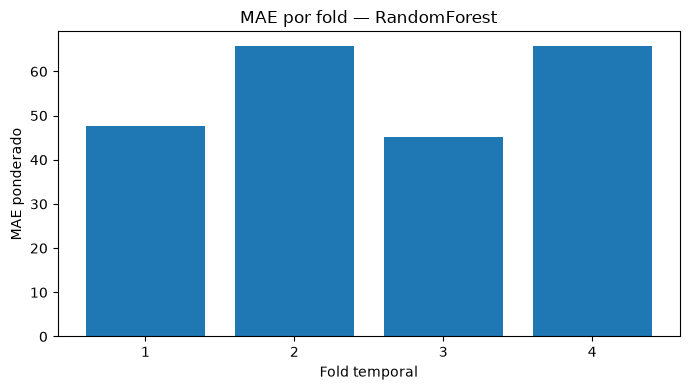

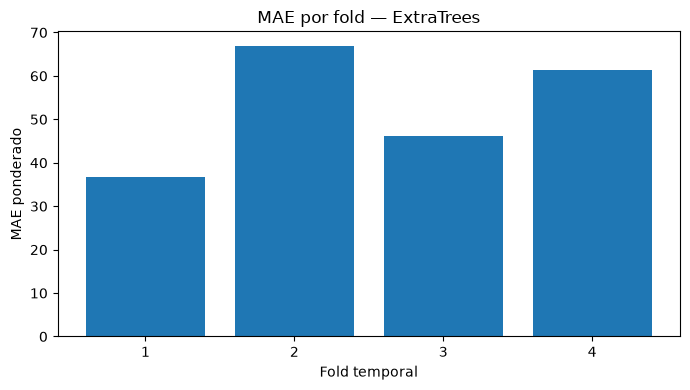

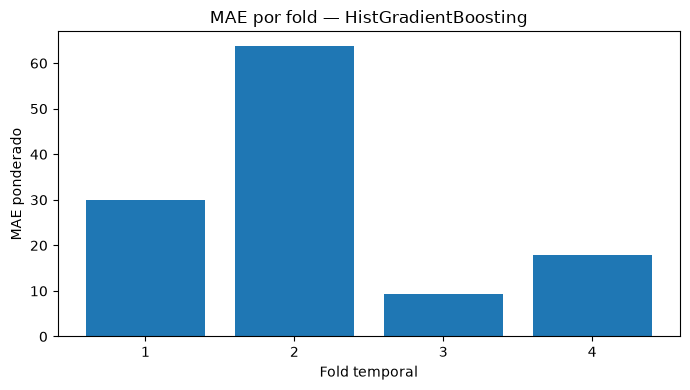

In [16]:
for model_name in reg_cv["modelo"].unique():
    temp = reg_cv[
        reg_cv["modelo"].eq(model_name)
    ]

    plt.figure(figsize=(7, 4))

    plt.bar(
        temp["fold"].astype(str),
        temp["mae_ponderado"],
    )

    plt.xlabel("Fold temporal")
    plt.ylabel("MAE ponderado")
    plt.title(
        f"MAE por fold — {model_name}"
    )

    plt.tight_layout()
    plt.show()

## 12. Treino final e avaliação no teste reservado

In [17]:
reg_dev = reg_all[
    reg_all["id_contrato"].isin(
        development_contracts
    )
].copy()

reg_test = reg_all[
    reg_all["id_contrato"].isin(
        test_contracts
    )
].copy()

best_reg_model = regression_models()[
    BEST_REGRESSION_MODEL
]

best_reg_model.fit(
    reg_dev[FEATURES],
    reg_dev["target_dias_atraso"].astype(float),
    model__sample_weight=reg_dev["sample_weight_contrato"].astype(float),
)

reg_test_pred = np.maximum(
    0,
    best_reg_model.predict(
        reg_test[FEATURES]
    ),
)

reg_test_results = pd.DataFrame([{
    "modelo": BEST_REGRESSION_MODEL,
    "split": "test",
    "contratos": reg_test["id_contrato"].nunique(),
    **regression_metrics(
        reg_test["target_dias_atraso"].astype(float),
        reg_test_pred,
        reg_test["sample_weight_contrato"].astype(float),
    ),
}])

display(reg_test_results)

,modelo,split,contratos,mae_ponderado,medae,rmse_ponderado,r2_ponderado,pct_erro_abs_ate_30d,erro_assinado_medio
0,HistGradientBoosting,test,8,21.875,0.0,54.351863,-0.193292,0.875,-21.875


## 13. Amostra das previsões

Mostra uma observação por contrato, aproximadamente 90 dias antes do prazo vigente.
Para manter coerência temporal, escolhemos o snapshot mais próximo que ainda tenha **pelo menos 90 dias restantes**.

In [18]:
amostra = reg_test[
    [
        "id_contrato",
        "data_corte",
        "dias_restantes_prazo_vigente",
        "target_dias_atraso",
    ]
].copy()

amostra["prev_dias_atraso"] = reg_test_pred

amostra = amostra[
    amostra["dias_restantes_prazo_vigente"].ge(90)
].copy()

amostra["dist_90d"] = (
    amostra["dias_restantes_prazo_vigente"] - 90
)

amostra = (
    amostra
    .sort_values(
        ["id_contrato", "dist_90d", "data_corte"]
    )
    .groupby("id_contrato", as_index=False)
    .first()
)

amostra["erro_dias"] = (
    amostra["prev_dias_atraso"]
    - amostra["target_dias_atraso"]
)

display(
    amostra[
        [
            "id_contrato",
            "data_corte",
            "dias_restantes_prazo_vigente",
            "target_dias_atraso",
            "prev_dias_atraso",
            "erro_dias",
        ]
    ].round(2)
)

C:\Users\Gabriel\AppData\Local\Temp\ipykernel_21348\2025519545.py:44: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,id_contrato,data_corte,dias_restantes_prazo_vigente,target_dias_atraso,prev_dias_atraso,erro_dias
0,173,2024-09-30,109,0.0,0.0,0.0
1,201,2024-11-30,102,0.0,0.0,0.0
2,254,2025-04-30,114,0.0,0.0,0.0
3,283,2024-11-30,97,0.0,0.0,0.0
4,287,2025-02-28,115,0.0,0.0,0.0
5,317,2024-10-31,114,23.0,0.0,-23.0
6,377,2025-04-29,90,152.0,0.0,-152.0


## 14. Avaliação por horizonte

Avalia uma previsão por contrato nos horizontes de 180, 90, 60 e 30 dias.

In [19]:
def selecionar_horizonte(data, pred, horizonte):
    temp = data[
        [
            "id_contrato",
            "data_corte",
            "dias_restantes_prazo_vigente",
            "target_dias_atraso",
            "sample_weight_contrato",
        ]
    ].copy()

    temp["pred"] = pred

    # Somente snapshots ainda anteriores ao horizonte.
    temp = temp[
        temp["dias_restantes_prazo_vigente"].ge(horizonte)
    ].copy()

    temp["dist"] = (
        temp["dias_restantes_prazo_vigente"] - horizonte
    )

    temp = (
        temp
        .sort_values(
            ["id_contrato", "dist", "data_corte"]
        )
        .groupby("id_contrato", as_index=False)
        .first()
    )

    return temp


horizon_rows = []

for horizonte in [180, 90, 60, 30]:
    h = selecionar_horizonte(
        reg_test,
        reg_test_pred,
        horizonte,
    )

    if len(h) == 0:
        continue

    horizon_rows.append({
        "horizonte_dias": horizonte,
        "contratos": h["id_contrato"].nunique(),
        **regression_metrics(
            h["target_dias_atraso"],
            h["pred"],
            h["sample_weight_contrato"],
        ),
    })

reg_horizon_results = pd.DataFrame(horizon_rows)

display(reg_horizon_results.round(4))

,horizonte_dias,contratos,mae_ponderado,medae,rmse_ponderado,r2_ponderado,pct_erro_abs_ate_30d,erro_assinado_medio
0,180,5,0.0000,0.0,0.000,1.0000,1.0000,0.0000
1,90,7,38.2329,0.0,72.930,-0.3790,0.7736,-38.2329
2,60,8,20.8904,0.0,53.909,-0.1767,0.8763,-20.8904
3,30,8,20.8904,0.0,53.909,-0.1767,0.8763,-20.8904


## 15. Importância das features

Random Forest e Extra Trees expõem importância por impureza.
Para HistGradientBoosting, esta seção apenas informa que a importância direta não está disponível.

Não use essa importância isoladamente para eliminar variáveis.

In [20]:
feature_importance = pd.DataFrame()

if BEST_REGRESSION_MODEL in {"RandomForest", "ExtraTrees"}:
    names = (
        best_reg_model["preprocessing"]
        .get_feature_names_out()
    )

    values = (
        best_reg_model["model"]
        .feature_importances_
    )

    feature_importance = (
        pd.DataFrame({
            "feature": names,
            "importancia": values,
        })
        .sort_values(
            "importancia",
            ascending=False,
        )
    )

    display(feature_importance.head(25))

else:
    print(
        "HistGradientBoosting não expõe feature_importances_ diretamente."
    )

HistGradientBoosting não expõe feature_importances_ diretamente.


## 16. Exportação

In [21]:
OUTPUT_DIR = Path(
    "/mnt/data/04R_regressao_14_features_outputs"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

pd.DataFrame({
    "feature": FEATURES,
    "tipo": [
        "numerica" if f in NUMERIC_FEATURES else "categorica"
        for f in FEATURES
    ],
}).to_csv(
    OUTPUT_DIR / "04R_features_14.csv",
    index=False,
    encoding="utf-8-sig",
)

fold_summary.to_csv(
    OUTPUT_DIR / "04R_folds_temporais.csv",
    index=False,
    encoding="utf-8-sig",
)

reg_cv.to_csv(
    OUTPUT_DIR / "04R_regressao_cv_folds.csv",
    index=False,
    encoding="utf-8-sig",
)

reg_cv_summary.to_csv(
    OUTPUT_DIR / "04R_regressao_cv_resumo.csv",
    index=False,
    encoding="utf-8-sig",
)

reg_test_results.to_csv(
    OUTPUT_DIR / "04R_regressao_teste_final.csv",
    index=False,
    encoding="utf-8-sig",
)

reg_horizon_results.to_csv(
    OUTPUT_DIR / "04R_regressao_horizontes_teste.csv",
    index=False,
    encoding="utf-8-sig",
)

amostra.to_csv(
    OUTPUT_DIR / "04R_amostra_previsoes_90d.csv",
    index=False,
    encoding="utf-8-sig",
)

if len(feature_importance):
    feature_importance.to_csv(
        OUTPUT_DIR / "04R_importancia_features.csv",
        index=False,
        encoding="utf-8-sig",
    )

print("Resultados salvos em:", OUTPUT_DIR)

Resultados salvos em: \mnt\data\04R_regressao_14_features_outputs


## Leitura recomendada

Compare principalmente:
1. MAE médio nos quatro folds;
2. desvio do MAE entre os folds;
3. erro assinado médio;
4. desempenho no teste final;
5. desempenho por horizonte.

A redução para 14 features só deve ser considerada superior se mantiver ou melhorar a generalização temporal, e não apenas o desempenho em um único período.